# Thesis prototype: Custom CNN (trained from scratch) + Transformer — P2datasetFull

This notebook trains a **Custom Residual CNN with Squeeze-and-Excitation (SE) attention**, built and trained **from scratch (no pretrained weights)**, combined with a **Transformer self-attention** block (Hybrid CNN-Transformer).
It produces accuracy / precision / recall / F1 / ROC-AUC outputs, similarity evidence, a human-review step, and a JSON review report.

## Dataset layout
```
MyDrive/ML-dataset/P2datasetFull/
    train/1   train/2
    val1/1    val1/2
    test1/1   test1/2
```

## Before running
1. **Runtime → Change runtime type → T4 GPU → Save.**
2. Run cells in order. After Cell 2, run the **GPU check** — it must NOT show `GPU: []`.
3. Training (Cell 3) takes a while. Keep the tab open. The best checkpoint is saved to Drive.
4. When finished, use **Runtime → Disconnect and delete runtime** to save GPU quota.

Important scope: folder 1 / folder 2 in P2datasetFull are labelled here as real / fake. Scores describe performance on this dataset only.

In [ ]:
# Cell 0: mount Google Drive and set configuration
from google.colab import drive
drive.mount("/content/drive")
from pathlib import Path
import os

DATASET_DIR = Path("/content/drive/MyDrive/ML-dataset/P2datasetFull")
SPLITS = ["train", "val1", "test1"]

# ⚠️ CHECK THIS: which folder is real and which is fake? Confirm with Cell 1b.
CLASS_MAP = {"1": "real", "2": "fake"}

LOCAL_ROOT = Path("/content/p2dataset_images")                     # fast local copy used for training
RESULTS_DIR = Path("/content/drive/MyDrive/ML-dataset/P2_results")  # charts, reports and model saved here
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert sorted(CLASS_MAP.values()) == ["fake", "real"], "CLASS_MAP must map one folder to 'real' and one to 'fake'"
for split in SPLITS:
    for folder in CLASS_MAP:
        p = DATASET_DIR / split / folder
        if not p.is_dir():
            raise FileNotFoundError(f"Missing folder {p}. Check DATASET_DIR and the folder names.")
print("Dataset found at", DATASET_DIR)
print("Class mapping:", CLASS_MAP)

Mounted at /content/drive
Dataset found at /content/drive/MyDrive/ML-dataset/P2datasetFull
Class mapping: {'1': 'real', '2': 'fake'}


In [ ]:
# Cell 1: copy images from Drive to local disk, checking every file is a readable image
# Reading from local disk is much faster than reading from Drive during training.
# Unreadable files are skipped and listed. Files with unusual formats (e.g. CMYK, PNG with transparency,
# WEBP saved as .jpg) are converted to RGB JPEG so TensorFlow can decode them; normal files are copied as-is.
import shutil
from PIL import Image
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
shutil.rmtree(LOCAL_ROOT, ignore_errors=True)

def process(task):
    src, dst_dir, idx = task
    try:
        with Image.open(src) as im:
            im.verify()
        with Image.open(src) as im:
            fmt, mode = im.format, im.mode
            if fmt in ("JPEG", "BMP", "PNG") and mode in ("RGB", "L"):
                ext = {"JPEG": ".jpg", "BMP": ".bmp", "PNG": ".png"}[fmt]
                shutil.copyfile(src, dst_dir / f"{idx:06d}{ext}")
                return "copied", src
            im.convert("RGB").save(dst_dir / f"{idx:06d}.jpg", quality=95)
            return "converted", src
    except Exception as e:
        return "skipped", f"{src} ({type(e).__name__})"

summary = {}
skipped_files = []
for split in SPLITS:
    for folder, class_name in CLASS_MAP.items():
        src_dir = DATASET_DIR / split / folder
        dst_dir = LOCAL_ROOT / split / class_name
        dst_dir.mkdir(parents=True, exist_ok=True)
        files = sorted(f for f in src_dir.iterdir() if f.suffix.lower() in VALID_EXT)
        tasks = [(f, dst_dir, i) for i, f in enumerate(files)]
        with ThreadPoolExecutor(max_workers=16) as pool:
            results = list(pool.map(process, tasks))
        counts = Counter(status for status, _ in results)
        skipped_files += [info for status, info in results if status == "skipped"]
        summary[(split, class_name)] = counts
        print(f"{split:6s} {class_name:5s} (folder {folder}): {dict(counts)}")

if skipped_files:
    print(f"\n{len(skipped_files)} unreadable files were skipped, e.g.:", skipped_files[:5])
data_root = str(LOCAL_ROOT)
print("\nPrepared labeled still images at", data_root)

train  real  (folder 1): {'copied': 3207}
train  fake  (folder 2): {'copied': 3051}
val1   real  (folder 1): {'copied': 3150}
val1   fake  (folder 2): {'copied': 3071}
test1  real  (folder 1): {'copied': 3171}
test1  fake  (folder 2): {'copied': 3075}

Prepared labeled still images at /content/p2dataset_images


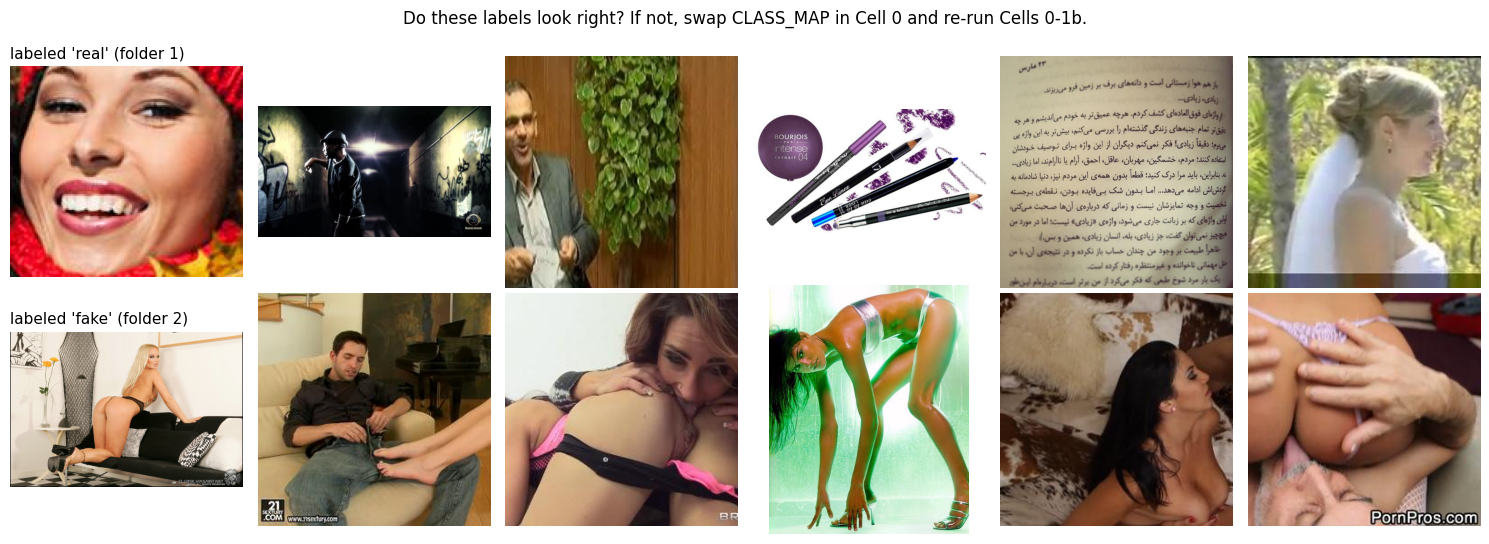

In [ ]:
# Cell 1b: view sample images from each class to CONFIRM the CLASS_MAP is correct
import matplotlib.pyplot as plt, random
random.seed(0)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for row, class_name in enumerate(["real", "fake"]):
    folder = [k for k, v in CLASS_MAP.items() if v == class_name][0]
    files = sorted((LOCAL_ROOT / "train" / class_name).iterdir())
    for ax, f in zip(axes[row], random.sample(files, 6)):
        ax.imshow(Image.open(f).convert("RGB")); ax.axis("off")
    axes[row][0].set_title(f"labeled '{class_name}' (folder {folder})", loc="left", fontsize=11)
plt.suptitle("Do these labels look right? If not, swap CLASS_MAP in Cell 0 and re-run Cells 0-1b.")
plt.tight_layout(); plt.show()

In [ ]:
# Cell 1c: check every image with TensorFlow's own decoder; repair or remove bad files
import tensorflow as tf
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

def tf_ok(p):
    try:
        tf.io.decode_image(tf.io.read_file(str(p)), channels=3, expand_animations=False)
        return True
    except Exception:
        return False

fixed, removed = [], []
for path in sorted(p for p in LOCAL_ROOT.rglob("*") if p.is_file()):
    if tf_ok(path):
        continue
    new_path = path.with_suffix(".jpg")
    try:
        with Image.open(path) as im:
            rgb = im.convert("RGB")
        rgb.save(new_path, quality=95)
        if new_path != path:
            path.unlink()
        if tf_ok(new_path):
            fixed.append(str(path)); continue
    except Exception:
        pass
    for p in {path, new_path}:
        p.unlink(missing_ok=True)
    removed.append(str(path))

print(f"Repaired: {len(fixed)}  Removed: {len(removed)}")
print("Examples:", (fixed + removed)[:5])

Repaired: 3  Removed: 0
Examples: ['/content/p2dataset_images/test1/fake/002875.jpg', '/content/p2dataset_images/train/fake/002019.jpg', '/content/p2dataset_images/val1/fake/003038.jpg']


In [ ]:
# Cell 2: load images; class order is real=0, manipulated/fake=1
import tensorflow as tf
IMG_SIZE = (224, 224); BATCH_SIZE = 32; SEED = 42
def load_split(split):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(data_root, split), class_names=["real", "fake"], label_mode="binary",
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=(split == "train"), seed=SEED)
train_ds = load_split("train").prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val1").prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test1").prefetch(tf.data.AUTOTUNE)
print("Class index 0 = real; class index 1 = fake")

Found 6258 files belonging to 2 classes.
Found 6221 files belonging to 2 classes.
Found 6246 files belonging to 2 classes.
Class index 0 = real; class index 1 = fake


In [ ]:
# GPU check: must show a GPU, not []. If [] -> Runtime > Change runtime type > T4 GPU
print("GPU:", tf.config.list_physical_devices("GPU"))
print("IMG_SIZE:", IMG_SIZE, "| BATCH_SIZE:", BATCH_SIZE, "| steps per epoch:", len(train_ds))
if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("Walang GPU! Runtime > Change runtime type > T4 GPU, then run again from Cell 0. Do NOT train on CPU.")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
IMG_SIZE: (224, 224) | BATCH_SIZE: 32 | steps per epoch: 196


In [ ]:
# Cell 3: Custom Residual CNN with SE attention (built and trained FROM SCRATCH, no pretrained weights)
#         + Transformer self-attention + fused embedding
from tensorflow.keras import layers, Model

def conv_bn(x, filters, kernel=3, strides=1):
    x = layers.Conv2D(filters, kernel, strides=strides, padding="same", use_bias=False, kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("swish")(x)

def se_block(x, ratio=8):
    # Squeeze-and-Excitation: learns which feature channels matter most
    ch = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(ch // ratio, activation="swish")(s)
    s = layers.Dense(ch, activation="sigmoid")(s)
    s = layers.Reshape((1, 1, ch))(s)
    return layers.Multiply()([x, s])

def residual_block(x, filters, strides=1):
    shortcut = x
    y = conv_bn(x, filters, 3, strides)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer="he_normal")(y)
    y = layers.BatchNormalization()(y)
    y = se_block(y)
    if strides != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=strides, use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    y = layers.Add()([y, shortcut])
    return layers.Activation("swish")(y)

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="face_image")
aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.05),
                           layers.RandomZoom(0.1), layers.RandomContrast(0.15)], name="augmentation")
x = aug(inputs)
x = layers.Rescaling(1.0 / 255, name="rescale")(x)
# Custom CNN backbone: 224 -> 112 -> 56 -> 28 -> 14 -> 7
x = conv_bn(x, 32, 3, 2)
x = residual_block(x, 64, 2);  x = residual_block(x, 64)
x = residual_block(x, 128, 2); x = residual_block(x, 128)
x = residual_block(x, 256, 2); x = residual_block(x, 256)
x = residual_block(x, 384, 2); x = residual_block(x, 384)
feature_map = layers.SpatialDropout2D(0.1, name="cnn_features")(x)
channels = int(feature_map.shape[-1])
# Transformer encoder block over the spatial tokens
tokens = layers.Reshape((-1, channels), name="spatial_tokens")(feature_map)
attn = layers.MultiHeadAttention(num_heads=4, key_dim=channels // 4, dropout=0.1, name="transformer_attention")(tokens, tokens)
tokens = layers.LayerNormalization(epsilon=1e-6)(tokens + attn)
mlp = layers.Dense(channels * 2, activation="gelu")(tokens)
mlp = layers.Dropout(0.1)(mlp)
mlp = layers.Dense(channels)(mlp)
tokens = layers.LayerNormalization(epsilon=1e-6)(tokens + mlp)
# Feature fusion: local CNN features + global Transformer features
global_features = layers.GlobalAveragePooling1D(name="transformer_pool")(tokens)
local_features = layers.GlobalAveragePooling2D(name="cnn_pool")(feature_map)
fused = layers.Concatenate(name="feature_fusion")([local_features, global_features])
embedding = layers.Dense(512, activation="relu", name="fused_embedding")(fused)
embedding = layers.Dropout(0.35)(embedding)
output = layers.Dense(1, activation="sigmoid", name="fake_probability")(embedding)
model = Model(inputs, output, name="custom_se_resnet_transformer")
embedding_model = Model(inputs, model.get_layer("fused_embedding").output, name="fused_embedding_model")
print("CNN feature map:", feature_map.shape, "(should be (None, 7, 7, 384))")
model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc"),
                       tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")])
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
             tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=2, min_lr=1e-5),
             tf.keras.callbacks.ModelCheckpoint(str(RESULTS_DIR / "checkpoint_custom_cnn.keras"), monitor="val_auc", mode="max", save_best_only=True)]
history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

CNN feature map: (None, 7, 7, 384) (should be (None, 7, 7, 384))
Epoch 1/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 89s 321ms/step - accuracy: 0.7701 - auc: 0.8393 - loss: 0.5145 - precision: 0.7588 - recall: 0.7745 - val_accuracy: 0.6028 - val_auc: 0.7781 - val_loss: 0.8192 - val_precision: 0.5555 - val_recall: 0.9775 - learning_rate: 0.0010
Epoch 2/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 53s 272ms/step - accuracy: 0.8258 - auc: 0.8963 - loss: 0.4076 - precision: 0.8203 - recall: 0.8230 - val_accuracy: 0.7787 - val_auc: 0.8935 - val_loss: 0.4958 - val_precision: 0.8977 - val_recall: 0.6226 - learning_rate: 0.0010
Epoch 3/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 57s 293ms/step - accuracy: 0.8348 - auc: 0.9091 - loss: 0.3840 - precision: 0.8267 - recall: 0.8364 - val_accuracy: 0.7905 - val_auc: 0.8936 - val_loss: 0.4433 - val_precision: 0.8410 - val_recall: 0.7099 - learning_rate: 0.0010
Epoch 4/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 61s 310ms/step - accuracy: 0.8469 - auc: 0.9205 - loss: 0.3594 - precision: 0.8473 - rec

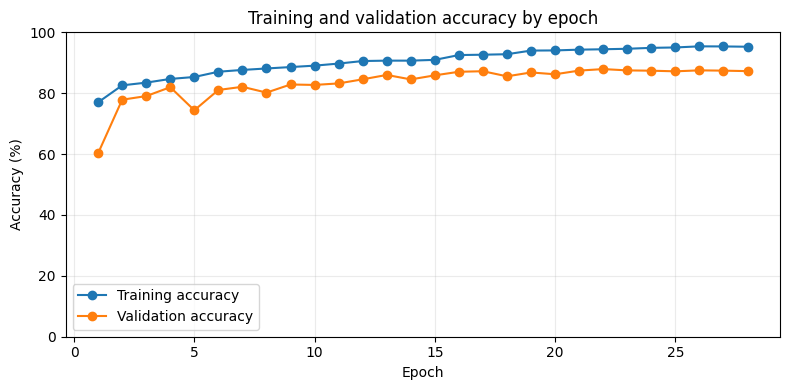

In [ ]:
# Cell 4: training and validation accuracy across epochs (not per-image accuracy)
import matplotlib.pyplot as plt
epochs = range(1, len(history.history["accuracy"]) + 1)
plt.figure(figsize=(8, 4))
plt.plot(epochs, [v * 100 for v in history.history["accuracy"]], marker="o", label="Training accuracy")
plt.plot(epochs, [v * 100 for v in history.history["val_accuracy"]], marker="o", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.ylim(0, 100)
plt.title("Training and validation accuracy by epoch"); plt.grid(alpha=0.25); plt.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "train_val_accuracy.png", dpi=160, bbox_inches="tight"); plt.show()

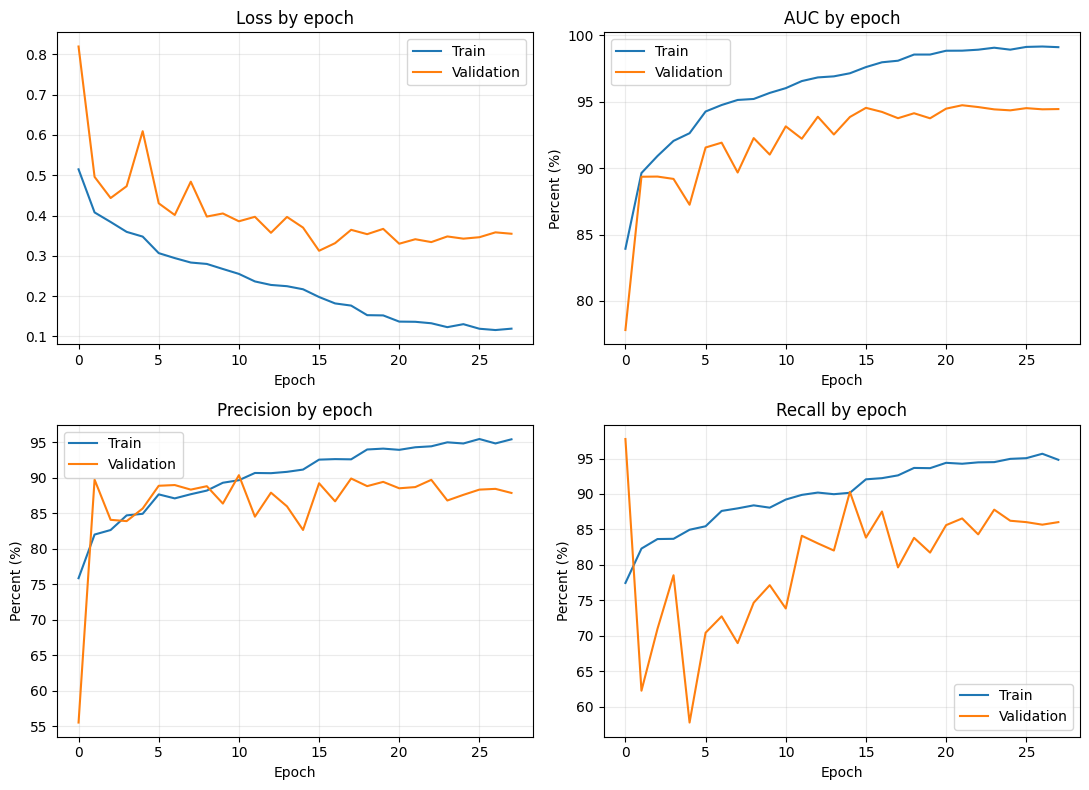

In [ ]:
# Cell 5: other learning curves
import numpy as np
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, key, title in zip(axes.flat, ["loss", "auc", "precision", "recall"], ["Loss", "AUC", "Precision", "Recall"]):
    scale = 1 if key == "loss" else 100
    ax.plot(np.array(history.history[key]) * scale, label="Train")
    ax.plot(np.array(history.history["val_" + key]) * scale, label="Validation")
    ax.set_title(title + " by epoch"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.25)
    if key != "loss": ax.set_ylabel("Percent (%)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "other_training_metrics.png", dpi=160, bbox_inches="tight"); plt.show()

In [ ]:
# Cell 6: evaluate on the held-out test1 images
results = model.evaluate(test_ds, return_dict=True, verbose=0)
print("Held-out test metrics (measured on test1 images):", results)
# Collect labels and predictions in a single pass so they stay aligned.
y_true, p_fake = [], []
for bx, by in test_ds:
    y_true.append(by.numpy().reshape(-1))
    p_fake.append(model.predict(bx, verbose=0).reshape(-1))
y_true = np.concatenate(y_true).astype(int); p_fake = np.concatenate(p_fake)
y_pred = (p_fake >= 0.5).astype(int)
matrix = np.zeros((2, 2), dtype=int); np.add.at(matrix, (y_true, y_pred), 1)
print("Class order: real, fake")
print("Confusion matrix (true rows, predicted columns):\n", matrix)
from sklearn.metrics import classification_report
report_text = classification_report(y_true, y_pred, target_names=["real", "fake"], digits=4)
print(report_text)
with open(RESULTS_DIR / "p2_test_report.txt", "w", encoding="utf-8") as f:
    f.write(f"Class mapping: {CLASS_MAP}\nClass order: real, fake\n{results}\n\nConfusion matrix:\n{matrix}\n\n{report_text}")

Held-out test metrics (measured on test1 images): {'accuracy': 0.8791226148605347, 'auc': 0.9461988210678101, 'loss': 0.34787318110466003, 'precision': 0.8924221992492676, 'recall': 0.8578861951828003}
Class order: real, fake
Confusion matrix (true rows, predicted columns):
 [[2853  318]
 [ 437 2638]]
              precision    recall  f1-score   support

        real     0.8672    0.8997    0.8831      3171
        fake     0.8924    0.8579    0.8748      3075

    accuracy                         0.8791      6246
   macro avg     0.8798    0.8788    0.8790      6246
weighted avg     0.8796    0.8791    0.8790      6246



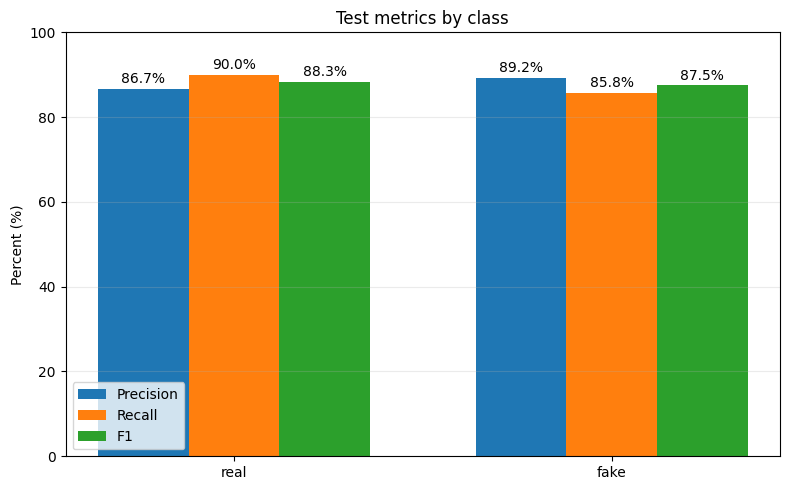

In [ ]:
# Cell 7: class precision, recall and F1 chart
names = ["real", "fake"]; support = matrix.sum(axis=1); colsum = matrix.sum(axis=0); diag = np.diag(matrix)
prec = np.divide(diag, colsum, out=np.zeros(2, dtype=float), where=colsum != 0)
rec = np.divide(diag, support, out=np.zeros(2, dtype=float), where=support != 0)
f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(2, dtype=float), where=(prec + rec) != 0)
fig, ax = plt.subplots(figsize=(8, 5)); x = np.arange(2); width = 0.24
ax.bar(x - width, prec * 100, width, label="Precision"); ax.bar(x, rec * 100, width, label="Recall"); ax.bar(x + width, f1 * 100, width, label="F1")
ax.set_xticks(x, names); ax.set_ylim(0, 100); ax.set_ylabel("Percent (%)"); ax.set_title("Test metrics by class")
for bars in ax.containers: ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.legend(); ax.grid(axis="y", alpha=0.25); plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_metrics_by_class.png", dpi=160, bbox_inches="tight"); plt.show()

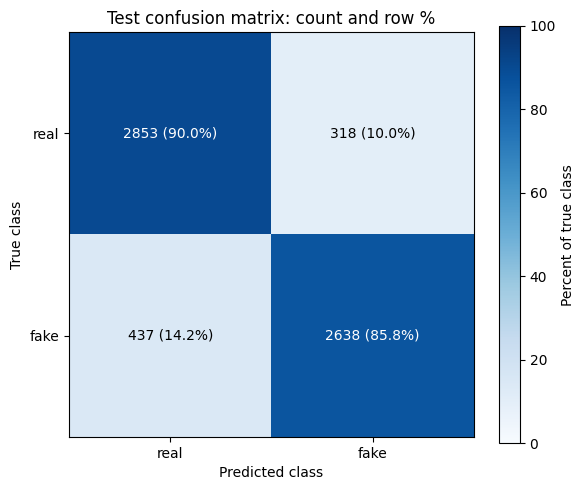

In [ ]:
# Cell 8: row-normalized confusion matrix
row_totals = matrix.sum(axis=1, keepdims=True)
percent_matrix = np.divide(matrix, row_totals, out=np.zeros_like(matrix, dtype=float), where=row_totals != 0) * 100
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(percent_matrix, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks([0, 1], ["real", "fake"]); ax.set_yticks([0, 1], ["real", "fake"])
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Test confusion matrix: count and row %")
for (i, j), v in np.ndenumerate(matrix):
    ax.text(j, i, f"{v} ({percent_matrix[i, j]:.1f}%)", ha="center", va="center",
            color="white" if percent_matrix[i, j] > 60 else "black")
fig.colorbar(im, ax=ax, label="Percent of true class"); plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_confusion_matrix.png", dpi=160, bbox_inches="tight"); plt.show()

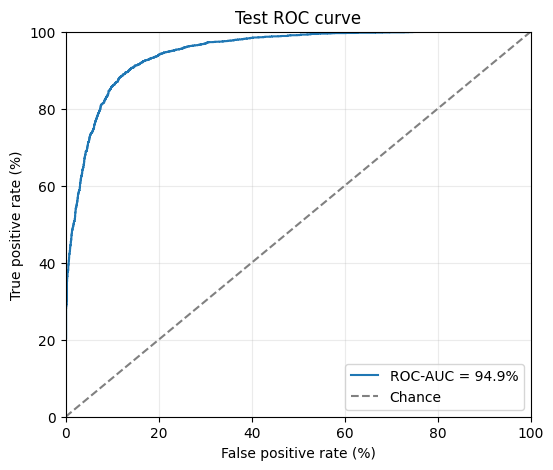

In [ ]:
# Cell 9: ROC curve
from sklearn.metrics import roc_curve, auc as sk_auc
fpr, tpr, _ = roc_curve(y_true, p_fake); roc_auc = float(sk_auc(fpr, tpr))
plt.figure(figsize=(6, 5)); plt.plot(fpr * 100, tpr * 100, label=f"ROC-AUC = {roc_auc * 100:.1f}%")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Chance")
plt.xlim(0, 100); plt.ylim(0, 100); plt.xlabel("False positive rate (%)"); plt.ylabel("True positive rate (%)")
plt.title("Test ROC curve"); plt.legend(loc="lower right"); plt.grid(alpha=0.25)
plt.savefig(RESULTS_DIR / "test_roc_curve.png", dpi=160, bbox_inches="tight"); plt.show()

In [ ]:
# Cell 10: save the trained model to Google Drive
model.save(RESULTS_DIR / "custom_cnn_transformer_p2.keras")
print("Model and charts saved in", RESULTS_DIR)

Model and charts saved in /content/drive/MyDrive/ML-dataset/P2_results


In [ ]:
# OPTIONAL Restore cell: use ONLY if the runtime restarted after training finished.
# Run Cells 0, 1, 1c, 2 first, then this cell, then Cell 11 (no retraining needed).
import numpy as np
from tensorflow.keras import Model
model_path = RESULTS_DIR / "custom_cnn_transformer_p2.keras"
if not model_path.exists():
    raise FileNotFoundError(f"Walang saved model sa {model_path}. Kailangang i-run ulit ang Cells 3-10.")
model = tf.keras.models.load_model(model_path)
embedding_model = Model(model.input, model.get_layer("fused_embedding").output, name="fused_embedding_model")
print("Loaded trained model from", model_path)

Loaded trained model from /content/drive/MyDrive/ML-dataset/P2_results/custom_cnn_transformer_p2.keras


In [ ]:
# Cell 11A: prepare reference images and analysis functions (run once)
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np, os, json
from tensorflow.keras.utils import load_img, img_to_array
from datetime import datetime, timezone
print("Decision support only: a trained reviewer makes the final determination.")
# Build small labeled reference galleries from the training split.
reference_images = {0: [], 1: []}
for bx, by in train_ds.unbatch().take(600):
    label = int(by.numpy().reshape(-1)[0] >= 0.5)
    if len(reference_images[label]) < 40: reference_images[label].append(bx.numpy())
ref_embeddings = {}
for label, images in reference_images.items():
    if images:
        embs = embedding_model.predict(np.stack(images), verbose=0)
        ref_embeddings[label] = (np.stack(images), embs)
# Mean embedding of all reference images; subtracting it removes features shared by all photos.
EMB_CENTER = np.concatenate([e for _, e in ref_embeddings.values()]).mean(axis=0)

def cosine_to_refs(ref_embs, query):
    a = ref_embs - EMB_CENTER
    q = query - EMB_CENTER
    return (a @ q) / np.maximum(np.linalg.norm(a, axis=1) * max(float(np.linalg.norm(q)), 1e-12), 1e-12)

def analyze_image(image_path):
    image = load_img(image_path, target_size=IMG_SIZE)
    arr = img_to_array(image).astype("float32")
    batch = arr[None, ...]
    p_fake = float(model.predict(batch, verbose=0)[0][0])
    query = embedding_model.predict(batch, verbose=0)[0]
    metrics = {}
    for label, name in [(0, "real"), (1, "fake")]:
        ref_imgs, ref_embs = ref_embeddings[label]
        norms = np.linalg.norm(ref_embs, axis=1) * max(float(np.linalg.norm(query)), 1e-12)
        raw_cosine = (ref_embs @ query) / np.maximum(norms, 1e-12)
        cosine = cosine_to_refs(ref_embs, query)
        distances = np.linalg.norm(ref_embs - query[None, :], axis=1)
        best = int(np.argmax(cosine))
        reference = tf.convert_to_tensor(ref_imgs[best:best + 1], dtype=tf.float32)
        ssim = float(tf.image.ssim(tf.convert_to_tensor(batch), reference, max_val=255.0)[0].numpy())
        metrics[name] = {"centered_cosine_similarity": round(float(cosine[best]), 4),
                         "raw_cosine_similarity_to_nearest_embedding": float(raw_cosine[best]),
                         "euclidean_distance_to_nearest_embedding": float(distances[best]),
                         "ssim_to_nearest_embedding_image": ssim}
    # Nearest-neighbour vote among the K most similar training references (both classes).
    K = 10
    all_embs = np.concatenate([ref_embeddings[0][1], ref_embeddings[1][1]])
    all_labels = np.array([0] * len(ref_embeddings[0][1]) + [1] * len(ref_embeddings[1][1]))
    top = np.argsort(-cosine_to_refs(all_embs, query))[:K]
    fake_votes = int(all_labels[top].sum())
    relative = {"real": round((K - fake_votes) / K * 100, 1), "fake": round(fake_votes / K * 100, 1),
                "k_nearest_references": K}
    predicted = "fake" if p_fake >= 0.5 else "real"
    return {"ai_suggestion": predicted, "fake_probability": p_fake,
            "confidence_percent": max(p_fake, 1 - p_fake) * 100,
            "relative_similarity_percent": relative, "similarity_evidence": metrics}

def print_summary(a):
    r, ev = a["relative_similarity_percent"], a["similarity_evidence"]
    print("=" * 60)
    print(f"AI suggestion        : {a['ai_suggestion'].upper()}")
    print(f"Fake probability     : {a['fake_probability'] * 100:.2f}%   (main basis of the AI suggestion)")
    print(f"Confidence           : {a['confidence_percent']:.2f}%")
    print(f"Nearest-reference vote: {r['real']:.0f}% REAL  |  {r['fake']:.0f}% FAKE  (top {r['k_nearest_references']} most similar training images)")
    print(f"Similarity to REAL   : {max(ev['real']['centered_cosine_similarity'], 0) * 100:.1f}%")
    print(f"Similarity to FAKE   : {max(ev['fake']['centered_cosine_similarity'], 0) * 100:.1f}%")
    print("=" * 60)
    print("Note: similarity is mean-centred cosine (shared photo features removed); negative values are shown as 0%.")
    print("It is supporting evidence, not a probability. Use fake_probability for the AI decision.\n")

print("Cell 11A ready. Now upload your photos and run Cell 11B.")

Decision support only: a trained reviewer makes the final determination.
Cell 11A ready. Now upload your photos and run Cell 11B.


Reviewer name: genesis


Saving train3 (1182).jpg to train3 (1182).jpg
Case ID for train3 (1182).jpg (e.g., CASE-0001): Case-001


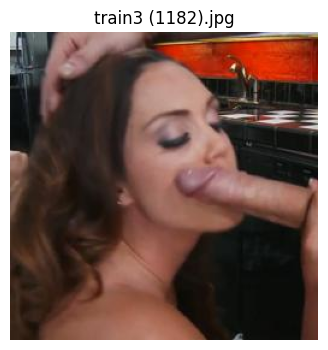

Case ID: Case-001
SHA-256: 8be5cd3689fcb14e77a6f5c2854948432ff5665ddd14452bcf40e1cf2d5d8d35
AI suggestion        : FAKE
Fake probability     : 99.47%   (main basis of the AI suggestion)
Confidence           : 99.47%
Nearest-reference vote: 10% REAL  |  90% FAKE  (top 10 most similar training images)
Similarity to REAL   : 98.1%
Similarity to FAKE   : 100.0%
Note: similarity is mean-centred cosine (shared photo features removed); negative values are shown as 0%.
It is supporting evidence, not a probability. Use fake_probability for the AI decision.

Reviewer decision (real/fake/further_review): fake
Reviewer rationale: fake
Forensic report saved to Google Drive: /content/drive/MyDrive/ML-dataset/P2_results/forensic_report_Case-001.json


In [ ]:
# Cell 11B: upload a photo -> AI analysis -> human review -> FORENSIC REPORT (with case ID + SHA-256 hash)
# Run Cell 11A first (it defines analyze_image and print_summary).
from google.colab import files
from tensorflow.keras.utils import load_img
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import hashlib, json

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

reviewer = input("Reviewer name: ").strip()
uploaded = files.upload()          # click "Choose Files" and pick one or more photos
for image_name in uploaded:
    image_hash = sha256_of(image_name)          # fingerprint of the ORIGINAL file (chain of custody)
    case_id = input(f"Case ID for {image_name} (e.g., CASE-0001): ").strip() or datetime.now().strftime("CASE-%Y%m%d-%H%M%S")
    plt.figure(figsize=(4, 4)); plt.imshow(load_img(image_name)); plt.axis("off"); plt.title(image_name); plt.show()
    analysis = analyze_image(image_name)        # the original file is only read, never modified
    print(f"Case ID: {case_id}\nSHA-256: {image_hash}")
    print_summary(analysis)
    decision = input("Reviewer decision (real/fake/further_review): ").strip().lower()
    while decision not in ("real", "fake", "further_review"):
        decision = input("Enter real, fake, or further_review: ").strip().lower()
    rationale = input("Reviewer rationale: ").strip()
    report = {
        "case_id": case_id,
        "reviewer": reviewer,
        "record_type": "forensic report (human-reviewed image analysis)",
        "image_filename": image_name,
        "image_sha256": image_hash,
        "dataset": "P2datasetFull",
        "class_mapping": CLASS_MAP,
        "model": "Custom SE-ResNet CNN (trained from scratch) + Transformer attention, P2datasetFull",
        **analysis,                              # AI analysis section
        "reviewer_final_decision": decision,     # human-verified section
        "reviewer_rationale": rationale,
        "interpretation_note": "fake_probability is the model's decision score. Similarity scores and the nearest-neighbour vote are supporting evidence, not calibrated probabilities or standalone proof of manipulation. Human review is required.",
        "reviewed_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    report_path = RESULTS_DIR / f"forensic_report_{case_id}.json"
    with open(report_path, "w", encoding="utf-8") as f:
        json.dump(report, f, indent=2, ensure_ascii=False)
    print("Forensic report saved to Google Drive:", report_path)

In [ ]:
# Cell 11B: upload a photo -> AI analysis -> human review -> FORENSIC REPORT (with case ID + SHA-256 hash)
# Run Cell 11A first (it defines analyze_image and print_summary).
from google.colab import files
from tensorflow.keras.utils import load_img
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import hashlib, json

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

reviewer = input("Reviewer name: ").strip()
uploaded = files.upload()          # click "Choose Files" and pick one or more photos
for image_name in uploaded:
    image_hash = sha256_of(image_name)          # fingerprint of the ORIGINAL file (chain of custody)
    case_id = input(f"Case ID for {image_name} (e.g., CASE-0001): ").strip() or datetime.now().strftime("CASE-%Y%m%d-%H%M%S")
    plt.figure(figsize=(4, 4)); plt.imshow(load_img(image_name)); plt.axis("off"); plt.title(image_name); plt.show()
    analysis = analyze_image(image_name)        # the original file is only read, never modified
    print(f"Case ID: {case_id}\nSHA-256: {image_hash}")
    print_summary(analysis)
    decision = input("Reviewer decision (real/fake/further_review): ").strip().lower()
    while decision not in ("real", "fake", "further_review"):
        decision = input("Enter real, fake, or further_review: ").strip().lower()
    rationale = input("Reviewer rationale: ").strip()
    report = {
        "case_id": case_id,
        "reviewer": reviewer,
        "record_type": "forensic report (human-reviewed image analysis)",
        "image_filename": image_name,
        "image_sha256": image_hash,
        "dataset": "P2datasetFull",
        "class_mapping": CLASS_MAP,
        "model": "Custom SE-ResNet CNN (trained from scratch) + Transformer attention, P2datasetFull",
        **analysis,                              # AI analysis section
        "reviewer_final_decision": decision,     # human-verified section
        "reviewer_rationale": rationale,
        "interpretation_note": "fake_probability is the model's decision score. Similarity scores and the nearest-neighbour vote are supporting evidence, not calibrated probabilities or standalone proof of manipulation. Human review is required.",
        "reviewed_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    report_path = RESULTS_DIR / f"forensic_report_{case_id}.json"
    with open(report_path, "w", encoding="utf-8") as f:
        json.dump(report, f, indent=2, ensure_ascii=False)
    print("Forensic report saved to Google Drive:", report_path)